In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import copy

In [ ]:
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
mean, std = 0.2860, 0.3530
test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_plain = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=test_tf)
train_aug = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=train_tf_aug)
test_ds = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=test_tf)

g = torch.Generator().manual_seed(0)
targets = train_plain.targets
val_idx, tr_idx = [], []
for c in range(10):
    idx = (targets == c).nonzero(as_tuple=True)[0]
    idx = idx[torch.randperm(len(idx), generator=g)]
    val_idx += idx[:1000].tolist()
    tr_idx  += idx[1000:].tolist()

train_ds_plain = Subset(train_plain, tr_idx)
train_ds_aug   = Subset(train_aug,   tr_idx)
val_ds         = Subset(train_plain, val_idx)

val_dl        = DataLoader(val_ds,         batch_size=256, shuffle=False)
train_eval_dl = DataLoader(train_ds_plain, batch_size=256, shuffle=False)
test_dl       = DataLoader(test_ds,        batch_size=256, shuffle=False)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 222kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.91MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 24.8MB/s]


In [ ]:
class MLP2(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )

    def forward(self, x):
        return self.net(x)

def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum/total, correct/total

In [ ]:
def run_training(model, train_dl, val_dl, epochs=30, lr=1e-3, weight_decay=0.0,
                    optimizer="adam", use_scheduler=False, patience=3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    if optimizer == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)

    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs//3), gamma=0.5) if use_scheduler else None

    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_loss, best_state, best_epoch, bad = float("inf"), None, 0, 0

    for epoch in range(1, epochs+1):
        model.train()
        run = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item()*yb.numel()

        if sched: sched.step()
        vl, va = evaluate(model, val_dl)
        hist["train_loss"].append(run/len(train_dl.dataset))
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        print(f"Epoka {epoch:2d} | trening {hist['train_loss'][-1]:.3f} | val {vl:.3f} | acc {va*100:.2f}%")

        if vl < best_loss - 1e-4:
            best_loss, best_epoch, bad = vl, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                print(f"Stop: brak poprawy od {patience} epok")
                break

    model.load_state_dict(best_state)
    print(f"Przywrócono wagi z epoki {best_epoch} (val_loss {best_loss:.3f})")
    return hist

BASELINE


In [ ]:
torch.manual_seed(0)
model_baseline = MLP2()
tr_dl = DataLoader(train_ds_plain, batch_size=128, shuffle=True)
hist_baseline = run_training(model_baseline, tr_dl, val_dl, epochs=15)

train_eval_loss, train_eval_acc = evaluate(model_baseline, train_eval_dl)
val_loss, val_acc = evaluate(model_baseline, val_dl)

print(f"\nWyniki modelu bazowego:")
print(f"-> Accuracy na walidacji: {val_acc*100:.2f}%")
print(f"-> Luka generalizacji (strata val - strata train): {val_loss - train_eval_loss:.3f}")

Epoka  1 | trening 0.503 | val 0.384 | acc 86.31%
Epoka  2 | trening 0.360 | val 0.340 | acc 87.50%
Epoka  3 | trening 0.320 | val 0.333 | acc 87.80%
Epoka  4 | trening 0.295 | val 0.320 | acc 88.36%
Epoka  5 | trening 0.273 | val 0.322 | acc 88.40%
Epoka  6 | trening 0.255 | val 0.358 | acc 87.33%
Epoka  7 | trening 0.244 | val 0.325 | acc 87.90%
Stop: brak poprawy od 3 epok
Przywrócono wagi z epoki 4 (val_loss 0.320)

Wyniki modelu bazowego:
-> Accuracy na walidacji: 88.36%
-> Luka generalizacji (strata val - strata train): 0.053


Ulepszenie nr 1: augumentacja

In [ ]:
torch.manual_seed(0)
model_aug = MLP2()
tr_dl_aug = DataLoader(train_ds_aug, batch_size=128, shuffle=True)
hist_aug = run_training(model_aug, tr_dl_aug, val_dl, epochs=15)

train_eval_loss_aug, _ = evaluate(model_aug, train_eval_dl)
val_loss_aug, val_acc_aug = evaluate(model_aug, val_dl)

print(f"\nWyniki modelu z augmentacją:")
print(f"-> Accuracy na walidacji: {val_acc_aug*100:.2f}%")
print(f"-> Luka generalizacji: {val_loss_aug - train_eval_loss_aug:.3f}")

Trenujemy z losowym odbiciem obrazków w poziomie.

Epoka  1 | trening 0.532 | val 0.419 | acc 84.53%
Epoka  2 | trening 0.376 | val 0.381 | acc 85.90%
Epoka  3 | trening 0.342 | val 0.342 | acc 87.40%
Epoka  4 | trening 0.316 | val 0.341 | acc 87.10%
Epoka  5 | trening 0.299 | val 0.328 | acc 88.06%
Epoka  6 | trening 0.283 | val 0.308 | acc 88.62%
Epoka  7 | trening 0.275 | val 0.302 | acc 88.91%
Epoka  8 | trening 0.259 | val 0.328 | acc 88.09%
Epoka  9 | trening 0.248 | val 0.303 | acc 88.87%
Epoka 10 | trening 0.241 | val 0.318 | acc 88.66%
Stop: brak poprawy od 3 epok
Przywrócono wagi z epoki 7 (val_loss 0.302)

Wyniki modelu z augmentacją:
-> Accuracy na walidacji: 88.91%
-> Luka generalizacji: 0.058


Ulepszenie nr 2: zamiana optymalizatora

In [ ]:
torch.manual_seed(0)
model_wd = MLP2()
hist_wd = run_training(model_wd, tr_dl, val_dl, epochs=15, optimizer="adamw", weight_decay=1e-2)

train_eval_loss_wd, _ = evaluate(model_wd, train_eval_dl)
val_loss_wd, val_acc_wd = evaluate(model_wd, val_dl)

print(f"\nWyniki modelu z AdamW:")
print(f"-> Accuracy na walidacji: {val_acc_wd*100:.2f}%")
print(f"-> Luka generalizacji: {val_loss_wd - train_eval_loss_wd:.3f}")

Zmieniamy optymalizator z Adam na AdamW i włączamy weight decay.

Epoka  1 | trening 0.503 | val 0.386 | acc 86.37%
Epoka  2 | trening 0.361 | val 0.339 | acc 87.51%
Epoka  3 | trening 0.321 | val 0.339 | acc 87.47%
Epoka  4 | trening 0.295 | val 0.316 | acc 88.51%
Epoka  5 | trening 0.275 | val 0.316 | acc 88.64%
Epoka  6 | trening 0.256 | val 0.348 | acc 87.72%
Epoka  7 | trening 0.247 | val 0.326 | acc 88.13%
Stop: brak poprawy od 3 epok
Przywrócono wagi z epoki 4 (val_loss 0.316)

Wyniki modelu z AdamW:
-> Accuracy na walidacji: 88.51%
-> Luka generalizacji: 0.052


Ulepszenie nr 3: scheduler StepLR

In [ ]:
torch.manual_seed(0)
model_sched = MLP2()
hist_sched = run_training(model_sched, tr_dl, val_dl, epochs=15, use_scheduler=True)

train_eval_loss_sched, _ = evaluate(model_sched, train_eval_dl)
val_loss_sched, val_acc_sched = evaluate(model_sched, val_dl)

print(f"\nWyniki modelu ze schedulerem:")
print(f"-> Accuracy na walidacji: {val_acc_sched*100:.2f}%")
print(f"-> Luka generalizacji: {val_loss_sched - train_eval_loss_sched:.3f}")

Trenujemy ze zmniejszającym się krok po kroku learning ratem.

Epoka  1 | trening 0.503 | val 0.384 | acc 86.31%
Epoka  2 | trening 0.360 | val 0.340 | acc 87.50%
Epoka  3 | trening 0.320 | val 0.333 | acc 87.80%
Epoka  4 | trening 0.295 | val 0.320 | acc 88.36%
Epoka  5 | trening 0.273 | val 0.322 | acc 88.40%
Epoka  6 | trening 0.232 | val 0.313 | acc 88.55%
Epoka  7 | trening 0.222 | val 0.301 | acc 89.05%
Epoka  8 | trening 0.209 | val 0.295 | acc 89.54%
Epoka  9 | trening 0.198 | val 0.298 | acc 89.39%
Epoka 10 | trening 0.189 | val 0.288 | acc 89.80%
Epoka 11 | trening 0.162 | val 0.284 | acc 90.03%
Epoka 12 | trening 0.153 | val 0.289 | acc 90.22%
Epoka 13 | trening 0.149 | val 0.290 | acc 90.15%
Epoka 14 | trening 0.142 | val 0.292 | acc 90.33%
Stop: brak poprawy od 3 epok
Przywrócono wagi z epoki 11 (val_loss 0.284)

Wyniki modelu ze schedulerem:
-> Accuracy na walidacji: 90.03%
-> Luka generalizacji: 0.134


#WIZUALIZACJA

Wykres dla baseline


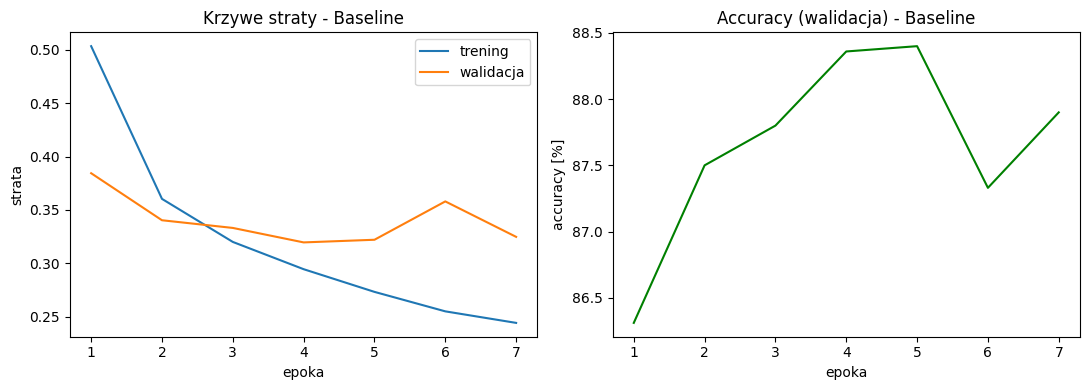

In [ ]:
hist = hist_baseline
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

epoki = range(1, len(hist["train_loss"]) + 1)

ax1.plot(epoki, hist["train_loss"], label="trening")
ax1.plot(epoki, hist["val_loss"], label="walidacja")
ax1.set_xlabel("epoka"); ax1.set_ylabel("strata"); ax1.legend(); ax1.set_title("Krzywe straty - Baseline")

ax2.plot(epoki, [a * 100 for a in hist["val_acc"]], color="green")
ax2.set_xlabel("epoka"); ax2.set_ylabel("accuracy [%]"); ax2.set_title("Accuracy (walidacja) - Baseline")

plt.tight_layout(); plt.show()

Wykres dla najlepszego modelu


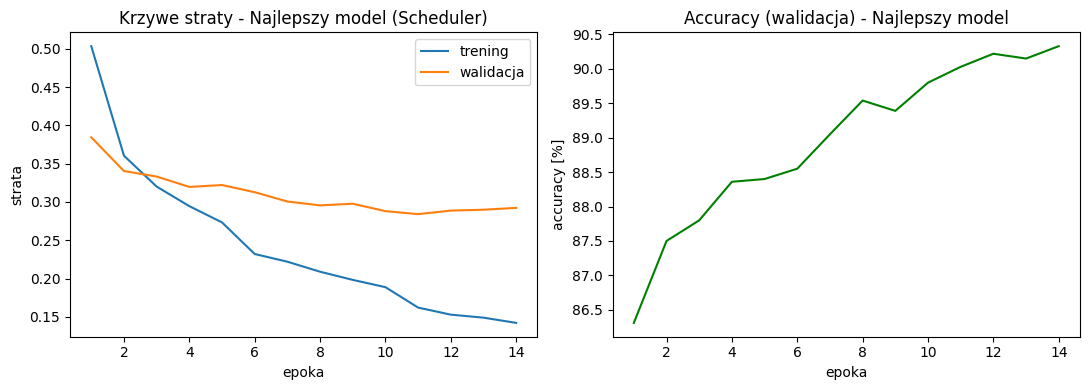

In [ ]:
hist = hist_sched
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

epoki = range(1, len(hist["train_loss"]) + 1)

ax1.plot(epoki, hist["train_loss"], label="trening")
ax1.plot(epoki, hist["val_loss"], label="walidacja")
ax1.set_xlabel("epoka"); ax1.set_ylabel("strata"); ax1.legend(); ax1.set_title("Krzywe straty - Najlepszy model (Scheduler)")

ax2.plot(epoki, [a * 100 for a in hist["val_acc"]], color="green")
ax2.set_xlabel("epoka"); ax2.set_ylabel("accuracy [%]"); ax2.set_title("Accuracy (walidacja) - Najlepszy model")

plt.tight_layout(); plt.show()

Ostateczna ewaluacja na zbiorze testowym


In [ ]:
test_loss, test_acc = evaluate(model_sched, test_dl)
print(f"Ostateczne Accuracy (test): {test_acc*100:.2f}%")
print(f"Ostateczna Strata (test): {test_loss:.3f}")

Ostateczne Accuracy (test): 89.30%
Ostateczna Strata (test): 0.321
